In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
df = pd.read_csv("../data/raw/listings.csv.gz")
df["price"] = df["price"].str.replace(r"[$,]", "", regex=True).astype(float)
df[["neighbourhood_cleansed", "room_type", "accommodates", "bedrooms", "price"]].describe(include="all")

,neighbourhood_cleansed,room_type,accommodates,bedrooms,price
count,15236,15236,15236.000000,15234.000000,12610.000000
unique,68,4,NaN,NaN,NaN
top,la Dreta de l'Eixample,Entire home/apt,NaN,NaN,NaN
freq,2186,10602,NaN,NaN,NaN
mean,NaN,NaN,3.672092,1.911382,253.414330
std,NaN,NaN,2.485188,1.478047,386.336426
min,NaN,NaN,1.000000,0.000000,12.810000
25%,NaN,NaN,2.000000,1.000000,93.385000
50%,NaN,NaN,3.000000,2.000000,190.670000
75%,NaN,NaN,5.000000,2.000000,284.000000


In [30]:
df.shape          # (rows, columns)
df.info()         # every column with its type and how many values are filled
df.sample(3, random_state=1).T

<class 'pandas.DataFrame'>
RangeIndex: 15236 entries, 0 to 15235
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            15236 non-null  int64  
 1   listing_url                                   15236 non-null  str    
 2   scrape_id                                     15236 non-null  int64  
 3   last_scraped                                  15236 non-null  str    
 4   source                                        3694 non-null   str    
 5   name                                          15236 non-null  str    
 6   description                                   15192 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   15236 non-null  str    
 9   host_id                                       15236 non-null  int64  
 1

,1436,11414,13950
id,8020706,1379741495234981855,1684623965995250872
listing_url,https://www.airbnb.com/rooms/8020706,https://www.airbnb.com/rooms/1379741495234981855,https://www.airbnb.com/rooms/1684623965995250872
scrape_id,20260917041147,20260917041147,20260917041147
last_scraped,2026-09-18,2026-09-18,2026-09-18
source,NaN,NaN,NaN
name,Incredible Lounge terrace best area,Room Paz - Cozy Single Room near Sagrada Familia,Alquilo por habitaciónes piso muy tranquilo
description,Welcome to one of the most exciting rooftop te...,"Welcome to Room Paz in Casa Botero, a cozy and...","Enjoy the simplicity of this quiet, centrally ..."
neighborhood_overview,NaN,NaN,NaN
picture_url,https://a0.muscache.com/pictures/102224654/8ad...,https://a0.muscache.com/pictures/prohost-api/H...,https://a0.muscache.com/pictures/hosting/Hosti...
host_id,40676061,221480824,272316032


In [31]:
df.isna().mean().sort_values(ascending=False)


neighborhood_overview                           1.000000
host_since                                      1.000000
host_response_time                              1.000000
host_thumbnail_url                              1.000000
host_acceptance_rate                            1.000000
host_response_rate                              1.000000
host_verifications                              1.000000
neighbourhood                                   1.000000
host_total_listings_count                       1.000000
host_neighbourhood                              1.000000
calendar_updated                                1.000000
instant_bookable                                1.000000
bathrooms                                       1.000000
source                                          0.757548
license                                         0.358756
host_about                                      0.315306
review_scores_accuracy                          0.216789
review_scores_value            

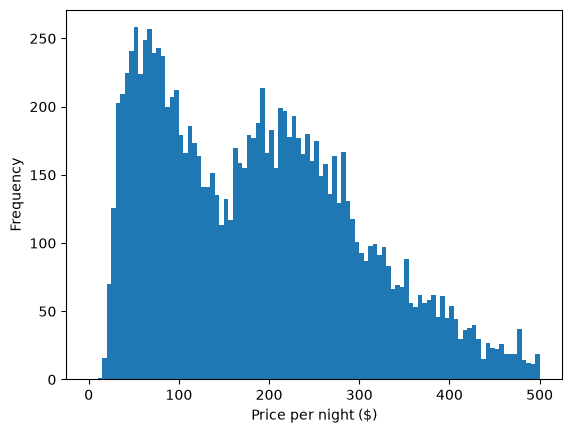

In [32]:
df["price"].describe()
df["price"].plot.hist(bins=100, range=(0, 500))
plt.xlabel("Price per night ($)")
plt.show()

room_type
Entire home/apt    10602
Private room        4430
Shared room          125
Hotel room            79
Name: count, dtype: int64


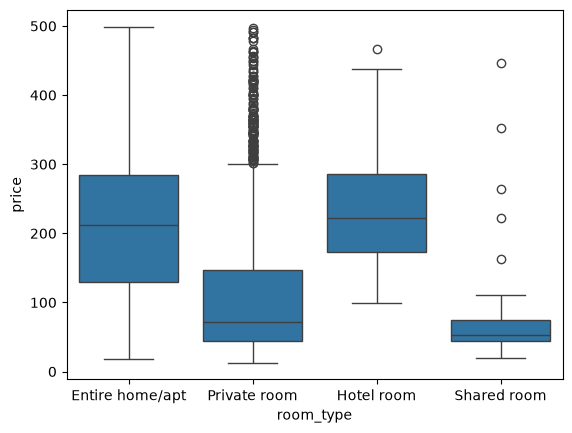

In [33]:
print(df["room_type"].value_counts())
sns.boxplot(data=df[df["price"] < 500], x="room_type", y="price")
plt.show()

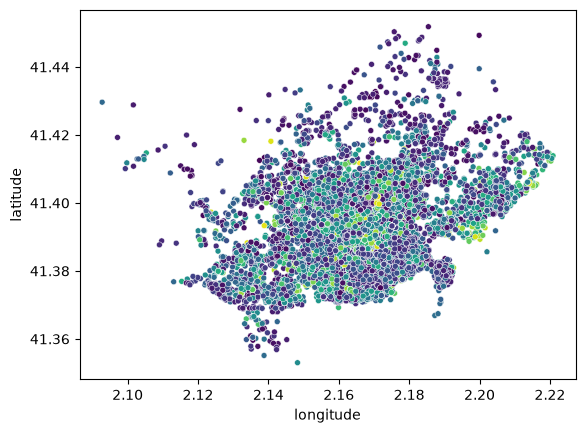

In [34]:
sns.scatterplot(data=df[df["price"] < 500], x="longitude", y="latitude",
                hue="price", size=1, palette="viridis", legend=False)
plt.show()